<a href="https://colab.research.google.com/github/EmmanueleVilla/quantum_computing/blob/main/Dungeon_Second_Solution_new_diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pylatexenc && pip install qiskit && pip install qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 21.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 38.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 37.1 MB/s  0:00:00


In [2]:
!pip install ipython-autotime
%load_ext autotime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 98.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ipython-autotime]
time: 333 µs (started: 2026-10-30 08:17:01 +00:00)


In [3]:
import math
import networkx as nx
import numpy as np
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.quantum_info import Statevector
from qiskit.visualization import circuit_drawer, plot_histogram
import matplotlib.pyplot as plt
from qiskit.circuit.library import MCXGate
from qiskit.circuit.library import QFT

time: 1.58 s (started: 2026-10-30 08:17:01 +00:00)


In [4]:
"""
Utility to normalize the state vector
"""
def normalize_state_vector(state_vector):
    non_negative_data = [max(val, 0) for val in state_vector.data]

    norm = np.linalg.norm(non_negative_data)

    normalized_state_vector = Statevector(non_negative_data) / norm

    return normalized_state_vector

time: 946 µs (started: 2026-10-30 08:17:02 +00:00)


## State Preparation

In [5]:
# Creates a 3x3 grid
G = nx.grid_2d_graph(3, 3)
mapping = {(i, j): i * 3 + j for i in range(3) for j in range(3)}
G = nx.relabel_nodes(G, mapping)

edges = list(G.edges())
undirected_edges = edges + [(v, u) for u, v in edges]

print(undirected_edges)

[(0, 3), (0, 1), (1, 4), (1, 2), (2, 5), (3, 6), (3, 4), (4, 7), (4, 5), (5, 8), (6, 7), (7, 8), (3, 0), (1, 0), (4, 1), (2, 1), (5, 2), (6, 3), (4, 3), (7, 4), (5, 4), (8, 5), (7, 6), (8, 7)]
time: 9.68 ms (started: 2026-10-30 08:17:02 +00:00)


In [6]:
# For each possible starting cell, I create a BFS circuit and save the state vector

state_vectors = []
for i in range(9):
    qc = QuantumCircuit(9, 9)
    qc.x(i)
    visited = []
    queue = [i]
    marked = [i]
    while len(queue) > 0:
        qc.barrier()
        current = queue.pop(0)
        visited.append(current)
        neighbors = [edge[1] for edge in undirected_edges if edge[0] == current]
        for neighbor in neighbors:
            if neighbor not in marked:
                qc.ch(current, neighbor)
                marked.append(neighbor)
            if neighbor not in visited and neighbor not in queue:
                queue.append(neighbor)

    state_vector_simulator = Aer.get_backend('statevector_simulator')
    transpiled = transpile(qc, state_vector_simulator)
    job = state_vector_simulator.run(transpiled)
    result = job.result()
    outputstate = result.get_statevector(transpiled, decimals=5)
    normalized = normalize_state_vector(outputstate)
    state_vectors.append(normalized)

    # Draw a circuit as an example
    if i == 0:
      circuit_to_draw = qc

# Adding measurements to the example circuit
circuit_to_draw.measure(range(9), range(9))


time: 1.51 s (started: 2026-10-30 08:17:02 +00:00)


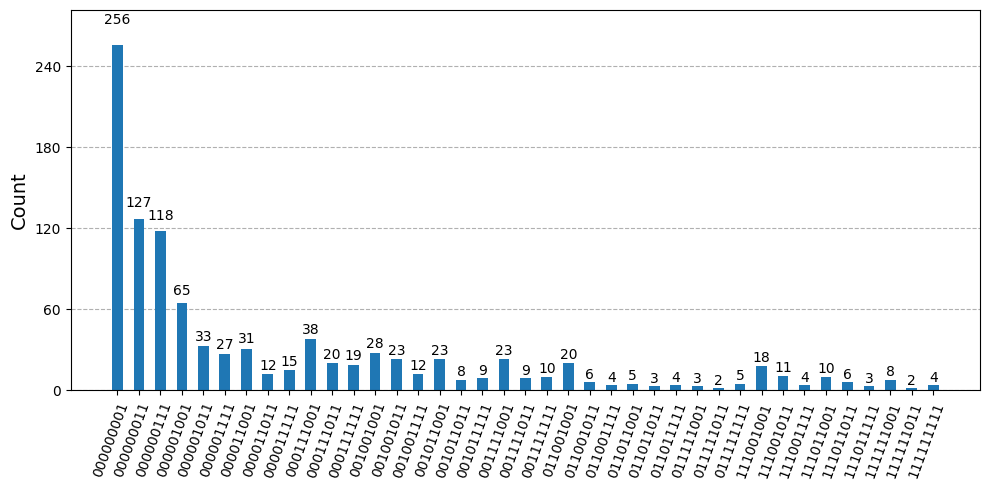

time: 1.12 s (started: 2026-10-30 08:17:04 +00:00)


In [7]:
# Run on simulator and plot counts
quantum_simulator = Aer.get_backend('qasm_simulator')
transpiled_circuit = transpile(circuit_to_draw, quantum_simulator)
job = quantum_simulator.run(transpiled_circuit, shots=1024)
counts = job.result().get_counts()

# Draw histogram of counts
plot_histogram(counts, figsize=(10, 5))

In [8]:
# Create the global state vector
global_state_vector = np.zeros(512)

for i in range(512):
    for state_vector in state_vectors:
        if global_state_vector[i] == 0 and not np.isclose(0, state_vector[i], atol=1e-8, rtol=0):
            global_state_vector[i] = 1

count_ones = np.sum(global_state_vector == 1)
print(f"'1' values in global_state_vector: {count_ones}")

'1' values in global_state_vector: 188
time: 224 ms (started: 2026-10-30 08:17:05 +00:00)


In [9]:
# State initialization
normalized_vector = np.asarray(global_state_vector) / np.linalg.norm(global_state_vector)

qc = QuantumCircuit(9, 9)
qc.initialize(normalized_vector, range(9))
basis_gates = ["u3", "u2", "u1", "cx", "id", "u", "p", "x", "y", "z", "h", "s", "sdg", "t", "tdg",
                            "rx", "ry", "rz", "sx", "sxdg", "cz", "cy", "swap", "ch", "ccx", "cswap", "crx", "cry"]
qc = transpile(qc, basis_gates=basis_gates)

qc_no_reset = QuantumCircuit(qc.num_qubits)
for index, instr in enumerate(qc.data):
  if instr[0].name != 'reset':
    qc_no_reset.append(instr[0], instr[1])

#qc_no_reset.draw("mpl")

time: 986 ms (started: 2026-10-30 08:17:05 +00:00)


/tmp/ipykernel_517/1522782524.py:12: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  if instr[0].name != 'reset':
/tmp/ipykernel_517/1522782524.py:13: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  qc_no_reset.append(instr[0], instr[1])


In [10]:
print("Gates count:" + str(dict(qc_no_reset.count_ops())))

Gates count:{'cx': 502, 'u3': 280, 'u2': 180, 'u1': 48, 'u': 3}
time: 1.19 ms (started: 2026-10-30 08:17:06 +00:00)


In [11]:
# Adding measurements
qc.measure(range(9), range(9))

time: 4.39 ms (started: 2026-10-30 08:17:06 +00:00)


In [12]:
# Testing the results - uniform probability
quantum_simulator = Aer.get_backend('qasm_simulator')
job = quantum_simulator.run(qc, shots=9**4)
result = job.result()
counts = result.get_counts()

time: 18.3 s (started: 2026-10-30 08:17:06 +00:00)


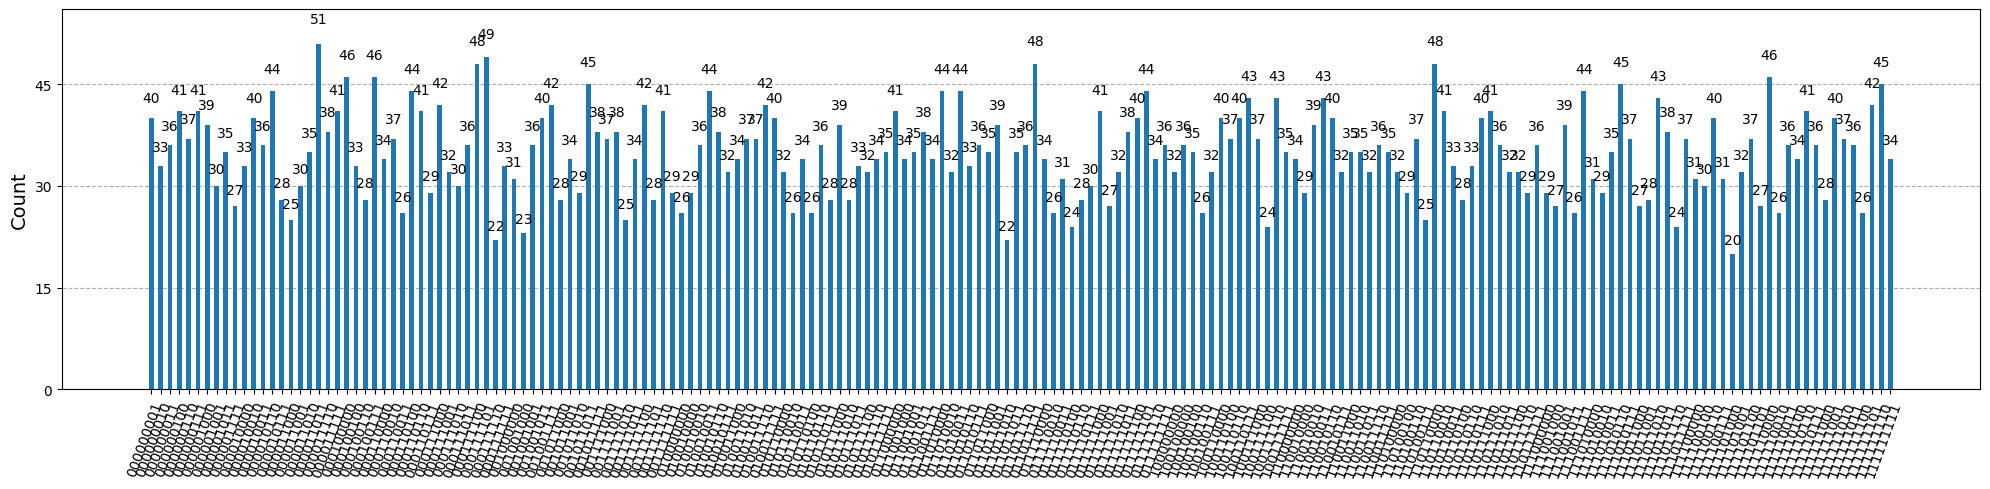

time: 1.46 s (started: 2026-10-30 08:17:25 +00:00)


In [13]:
plot_histogram(counts, figsize=(20, 5))

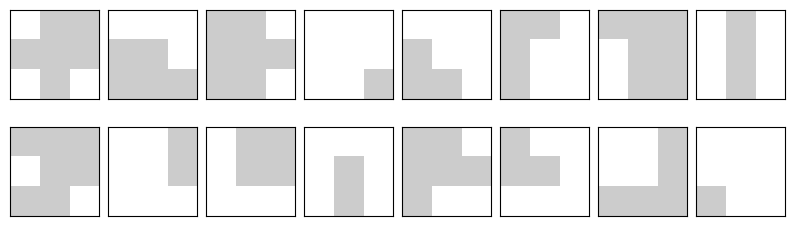

time: 326 ms (started: 2026-10-30 08:17:26 +00:00)


In [14]:
# Testing the results - printing some dungeon
keys = list(counts.keys())

fig, ax = plt.subplots(2, 8, figsize=(10, 3), subplot_kw={"xticks": [], "yticks": []})
for i in range(16):
    ax[i // 8, i % 8].imshow(
        np.array([int(x) for x in keys[i]]).reshape(3, 3),
        aspect="equal",
        cmap='gray_r',
        vmax=5
    )
plt.subplots_adjust(wspace=0.1, hspace=0.025)

In [15]:
# Creating the state_prep and inverse to be used in Grover
stat_prep = qc_no_reset.to_instruction()
inv_stat_prep = qc_no_reset.inverse().to_instruction()

time: 7.87 ms (started: 2026-10-30 08:17:26 +00:00)


## Diffusion circuit

In [16]:
def q(qc, num_control, node, anc):
  qc.ccx(node[0], node[1], anc[0])
  for i in range(num_control - 2):
      qc.ccx(node[i + 2], anc[i], anc[i + 1])
  qc.cz(anc[num_control - 2], node[num_control])
  for i in range(num_control - 2)[::-1]:
      qc.ccx(node[i + 2], anc[i], anc[i + 1])
  qc.ccx(node[0], node[1], anc[0])

time: 917 µs (started: 2026-10-30 08:17:26 +00:00)


:## Full Circuit for dungeons with length 4 and rooms in the cells 0 and 1 - 4 iterations

In [17]:
# Registers
graph = QuantumRegister(9, 'graph')
oracle = QuantumRegister(1, 'oracle')
const_anc = QuantumRegister(2, 'c_anc')
counts = QuantumRegister(3, 'count')
anc = QuantumRegister(7, 'anc_diff')
c = ClassicalRegister(9, 'c')

qc = QuantumCircuit(graph, const_anc, oracle, counts, anc, c)

qc.barrier(label="State preparation")
qc.append(stat_prep, graph)

qc.barrier(label="Oracle preparation")
qc.x(oracle)
qc.h(oracle)

num_iterations = 1

for i in range(num_iterations):

  # I want all the dungeons with the first two square checked
  # (using 7 and 8 because qiskit measures in the opposite direction)
  qc.barrier(label="Oracle")
  qc.ccx(graph[7], graph[8], const_anc[0])
  qc.barrier()

  # Now I want to count how many rooms there are in the 3 count qubits
  qc.h(counts)
  qc.barrier()
  for qubit in graph:
    qc.crz(np.pi/4, qubit, counts[0])
    qc.crz(np.pi/2, qubit, counts[1])
    qc.crz(np.pi, qubit, counts[2])
    qc.barrier()

  qft = QFT(3, do_swaps=True, inverse=True)
  qc.append(qft.to_instruction(), counts)

  # And check if the rooms are 4 = '100'
  mcx = MCXGate(3, "count", "100")

  qc.append(mcx, qargs=[counts[0], counts[1], counts[2], const_anc[1]])

  qc.barrier()

  # I now attach the constraint ancillas to the oracle register
  qc.ccx(const_anc[0], const_anc[1], oracle[0])

  qc.barrier()

  qc.append(mcx, qargs=[counts[0], counts[1], counts[2], const_anc[1]])

  qc.append(qft.inverse().to_instruction(), counts)

  # Then I reset the oracle
  for qubit in graph:
    qc.crz(-np.pi, qubit, counts[2])
    qc.crz(-np.pi/2, qubit, counts[1])
    qc.crz(-np.pi/4, qubit, counts[0])
    qc.barrier()

  qc.h(counts)
  qc.barrier()

  qc.ccx(graph[7], graph[8], const_anc[0])

  qc.barrier(label="Diffusion")

  # inv state preparation + x
  qc.append(inv_stat_prep, range(9))
  qc.x(range(9))

  qc.barrier()

  # Multi-controlled Z
  cnz(qc, 8, graph[::-1], anc)

  qc.barrier()

  # x + state preparation
  qc.x(range(9))
  qc.append(stat_prep, range(9))

# Measurement
qc.measure(graph, c)

#qc.draw("mpl")

/tmp/ipykernel_517/2787162031.py:37: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft = QFT(3, do_swaps=True, inverse=True)


time: 10.3 ms (started: 2026-10-30 08:17:26 +00:00)


In [18]:
# Transpiling the circuit for the target simulator
quantum_simulator = Aer.get_backend('qasm_simulator')
transpiled = transpile(qc, quantum_simulator)

time: 1.06 s (started: 2026-10-30 08:17:26 +00:00)


In [19]:
job = quantum_simulator.run(transpiled, shots=5)
result = job.result()
counts = result.get_counts()

time: 29.7 s (started: 2026-10-30 08:17:27 +00:00)


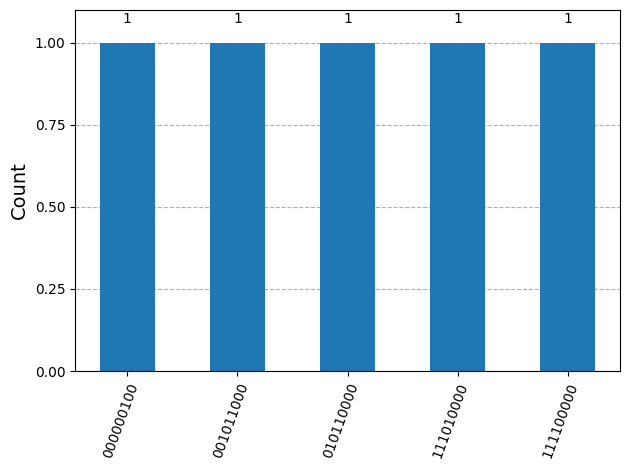

time: 111 ms (started: 2026-10-30 08:17:57 +00:00)


In [20]:
plot_histogram(counts)

### 9^4 measurements

In [21]:
job = quantum_simulator.run(transpiled, shots=9**3)
result = job.result()
counts = result.get_counts()


time: 29 s (started: 2026-10-30 08:17:57 +00:00)


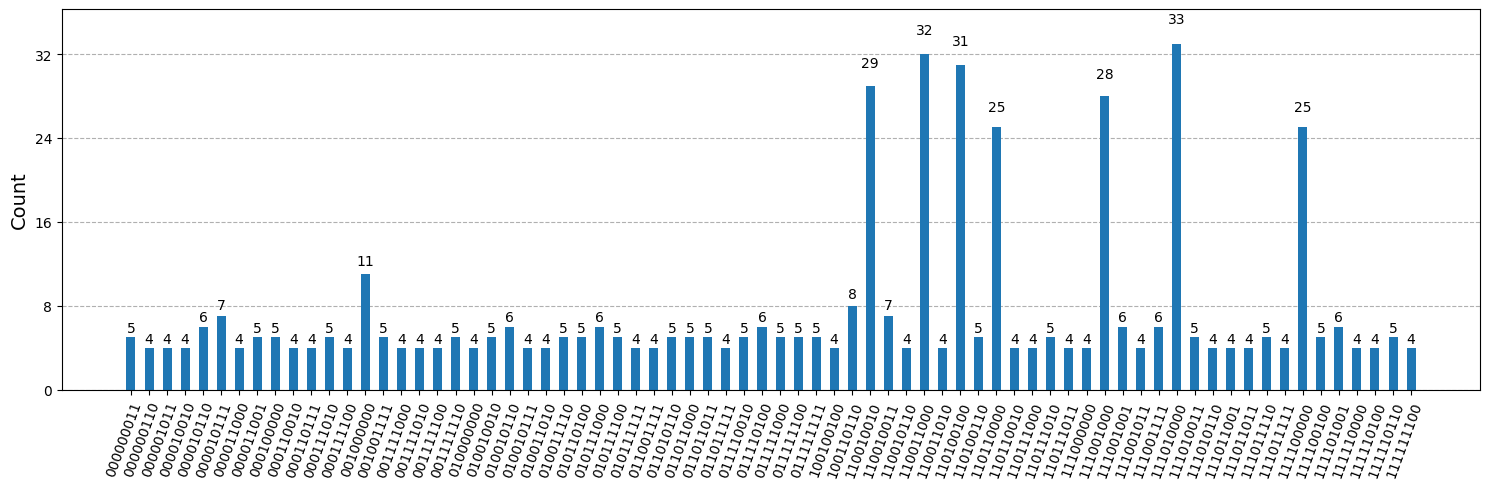

time: 551 ms (started: 2026-10-30 08:18:26 +00:00)


In [22]:
counts = {k: v for k, v in counts.items() if v >= 4}
plot_histogram(counts, figsize=(15, 5))

## Full Circuit for dungeons with length 4 and rooms in the cells 0 and 1 - 3 iterations

/tmp/ipykernel_517/2284313589.py:37: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft = QFT(3, do_swaps=True, inverse=True)
/tmp/ipykernel_517/2284313589.py:37: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft = QFT(3, do_swaps=True, inverse=True)
/tmp/ipykernel_517/2284313589.py:37: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous argum

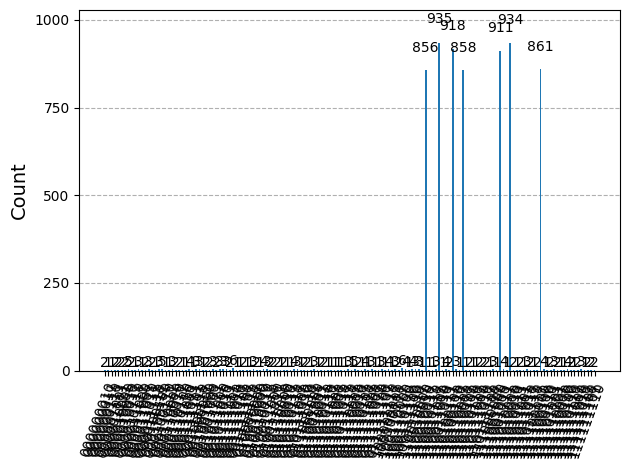

time: 1min 11s (started: 2026-10-30 08:18:27 +00:00)


In [23]:
# Registers
graph = QuantumRegister(9, 'graph')
oracle = QuantumRegister(1, 'oracle')
const_anc = QuantumRegister(2, 'c_anc')
counts = QuantumRegister(3, 'count')
anc = QuantumRegister(7, 'anc_diff')
c = ClassicalRegister(9, 'c')

qc = QuantumCircuit(graph, const_anc, oracle, counts, anc, c)

qc.barrier(label="State preparation")
qc.append(stat_prep, graph)

qc.barrier(label="Oracle preparation")
qc.x(oracle)
qc.h(oracle)

num_iterations = 3

for i in range(num_iterations):

  # I want all the dungeons with the first two square checked
  # (using 7 and 8 because qiskit measures in the opposite direction)
  qc.barrier(label="Oracle")
  qc.ccx(graph[7], graph[8], const_anc[0])
  qc.barrier()

  # Now I want to count how many rooms there are in the 3 count qubits
  qc.h(counts)
  qc.barrier()
  for qubit in graph:
    qc.crz(np.pi/4, qubit, counts[0])
    qc.crz(np.pi/2, qubit, counts[1])
    qc.crz(np.pi, qubit, counts[2])
    qc.barrier()

  qft = QFT(3, do_swaps=True, inverse=True)
  qc.append(qft.to_instruction(), counts)

  # And check if the rooms are 4 = '100'
  mcx = MCXGate(3, "count", "100")

  qc.append(mcx, qargs=[counts[0], counts[1], counts[2], const_anc[1]])

  qc.barrier()

  # I now attach the constraint ancillas to the oracle register
  qc.ccx(const_anc[0], const_anc[1], oracle[0])

  qc.barrier()

  qc.append(mcx, qargs=[counts[0], counts[1], counts[2], const_anc[1]])

  qc.append(qft.inverse().to_instruction(), counts)

  # Then I reset the oracle
  for qubit in graph:
    qc.crz(-np.pi, qubit, counts[2])
    qc.crz(-np.pi/2, qubit, counts[1])
    qc.crz(-np.pi/4, qubit, counts[0])
    qc.barrier()

  qc.h(counts)
  qc.barrier()

  qc.ccx(graph[7], graph[8], const_anc[0])

  qc.barrier(label="Diffusion")

  # inv state preparation + x
  qc.append(inv_stat_prep, range(9))
  qc.x(range(9))

  qc.barrier()

  # Multi-controlled Z
  cnz(qc, 8, graph[::-1], anc)

  qc.barrier()

  # x + state preparation
  qc.x(range(9))
  qc.append(stat_prep, range(9))

# Measurement
qc.measure(graph, c)

# Transpiling the circuit for the target simulator
quantum_simulator = Aer.get_backend('qasm_simulator')
transpiled = transpile(qc, quantum_simulator)

job = quantum_simulator.run(transpiled, shots=9**4)
result = job.result()
counts = result.get_counts()

plot_histogram(counts)

## Reducing qubit number by "recycling" the qubits already used after uncomputing them, also putting impossible constraints to show the results





/tmp/ipykernel_517/3497390580.py:34: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft = QFT(3, do_swaps=True, inverse=True)
/tmp/ipykernel_517/3497390580.py:34: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft = QFT(3, do_swaps=True, inverse=True)
/tmp/ipykernel_517/3497390580.py:34: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous argum

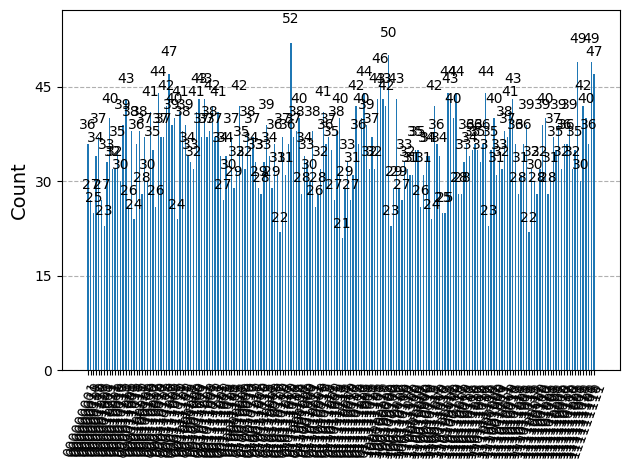

time: 5.93 s (started: 2026-10-30 08:19:38 +00:00)


In [24]:
# Registers
graph = QuantumRegister(9, 'graph')
oracle = QuantumRegister(1, 'oracle')
anc = QuantumRegister(7, 'anc_diff')
c = ClassicalRegister(9, 'c')

qc = QuantumCircuit(graph, oracle, anc, c)

qc.barrier(label="State preparation")
qc.append(stat_prep, graph)

qc.barrier(label="Oracle preparation")
qc.x(oracle)
qc.h(oracle)

num_iterations = 3

for i in range(num_iterations):

  # I want all the dungeons with the opposite cells occupied
  qc.barrier(label="Oracle")
  qc.ccx(graph[0], graph[8], anc[0])
  qc.barrier()

  # Now I want to count how many rooms there are in the 3 count qubits
  qc.h([anc[2], anc[3], anc[4]])
  qc.barrier()
  for qubit in graph:
    qc.crz(np.pi/4, qubit, anc[2])
    qc.crz(np.pi/2, qubit, anc[3])
    qc.crz(np.pi, qubit, anc[4])
    qc.barrier()

  qft = QFT(3, do_swaps=True, inverse=True)
  qc.append(qft.to_instruction(), [anc[2], anc[3], anc[4]])

  # And check if the rooms are 4 = '100'
  mcx = MCXGate(3, "count", "100")

  qc.append(mcx, qargs=[anc[2], anc[3], anc[4], anc[1]])

  qc.barrier()

  # I now attach the constraint ancillas to the oracle register
  qc.ccx(anc[0], anc[1], oracle[0])

  qc.barrier()

  qc.append(mcx, qargs=[anc[2], anc[3], anc[4], anc[1]])

  qc.append(qft.inverse().to_instruction(), [anc[2], anc[3], anc[4]])

  # Then I reset the oracle
  for qubit in graph:
    qc.crz(-np.pi, qubit, anc[4])
    qc.crz(-np.pi/2, qubit, anc[3])
    qc.crz(-np.pi/4, qubit, anc[2])
    qc.barrier()

  qc.h([anc[2], anc[3], anc[4]])
  qc.barrier()

  qc.ccx(graph[0], graph[8], anc[0])  # in FIX: uncompute must use the same controls (0, 8) used to compute anc[0]

  qc.barrier(label="Diffusion")

  # inv state preparation + x
  qc.append(inv_stat_prep, range(9))
  qc.x(range(9))

  qc.barrier()

  # Multi-controlled Z
  cnz(qc, 8, graph[::-1], anc)

  qc.barrier()

  # x + state preparation
  qc.x(range(9))
  qc.append(stat_prep, range(9))

# Measurement
qc.measure(graph, c)

# Transpiling the circuit for the target simulator
quantum_simulator = Aer.get_backend('qasm_simulator')
transpiled = transpile(qc, quantum_simulator)

job = quantum_simulator.run(transpiled, shots=9**4)
result = job.result()
counts = result.get_counts()

plot_histogram(counts)

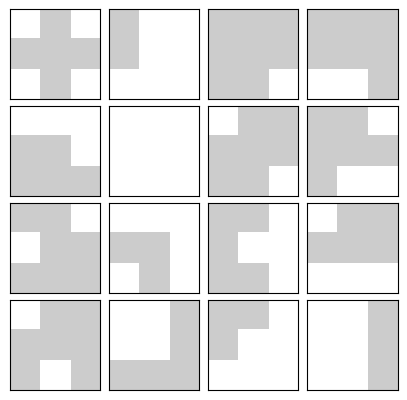

time: 300 ms (started: 2026-10-30 08:19:44 +00:00)


In [25]:
# Testing the results - printing some dungeon with high count
# Top 16 outcomes (with the uncompute fix and impossible constraints the distribution is ~uniform: no count > 150)
keys = sorted(counts, key=counts.get, reverse=True)[:16]

fig, ax = plt.subplots(4, 4, figsize=(5, 5), subplot_kw={"xticks": [], "yticks": []})
for i in range(16):
  ax[i // 4, i % 4].imshow(
      np.array([int(x) for x in keys[i]]).reshape(3, 3),
      aspect="equal",
      cmap='gray_r',
      vmax=5
  )
plt.subplots_adjust(wspace=0.1, hspace=0.025)

In [30]:
# ===== 1) Complexity of the "recycling" circuit with the two diffusions (uncompute bug fixed) =====
import json, warnings, time
import pandas as pd
from qiskit.circuit.library import ZGate, XGate
from qiskit.quantum_info import Statevector
warnings.filterwarnings("ignore", category=DeprecationWarning)

def build_recycling_circuit(num_iterations, diffusion="ancilla", n_anc=None):
    """Same circuit as the 'Reducing qubit number by recycling...' section (with the anc[0] uncompute fixed).
    diffusion='ancilla' -> inv_stat_prep + X + cnz (7 ancillas, Toffoli chain) + X + stat_prep
    diffusion='mcz'     -> inv_stat_prep + X + ZGate().control(8) (no ancillas) + X + stat_prep
    diffusion='mcx'     -> inv_stat_prep + X + H(q0) + C^8X(target q0) + H(q0) + X + stat_prep (no ancillas)
    n_anc: size of the anc register (default 7 for 'ancilla', 5 = only the oracle ones for 'mcz')"""
    if n_anc is None:
        n_anc = 7 if diffusion == "ancilla" else 5
    graph = QuantumRegister(9, 'graph')
    oracle = QuantumRegister(1, 'oracle')
    anc = QuantumRegister(n_anc, 'anc_diff')
    c = ClassicalRegister(9, 'c')
    qc = QuantumCircuit(graph, oracle, anc, c)

    qc.append(stat_prep, graph)
    qc.x(oracle)
    qc.h(oracle)

    qft = QFT(3, do_swaps=True, inverse=True)
    mcx = MCXGate(3, "count", "100")
    cnt = [anc[2], anc[3], anc[4]]
    for _ in range(num_iterations):
        # Oracle
        qc.ccx(graph[0], graph[8], anc[0])
        qc.h(cnt)
        for qubit in graph:
            qc.crz(np.pi/4, qubit, anc[2])
            qc.crz(np.pi/2, qubit, anc[3])
            qc.crz(np.pi, qubit, anc[4])
        qc.append(qft.to_instruction(), cnt)
        qc.append(mcx, qargs=cnt + [anc[1]])
        qc.ccx(anc[0], anc[1], oracle[0])
        qc.append(mcx, qargs=cnt + [anc[1]])
        qc.append(qft.inverse().to_instruction(), cnt)
        for qubit in graph:
            qc.crz(-np.pi, qubit, anc[4])
            qc.crz(-np.pi/2, qubit, anc[3])
            qc.crz(-np.pi/4, qubit, anc[2])
        qc.h(cnt)
        qc.ccx(graph[0], graph[8], anc[0])   # FIX: was graph[7], graph[8] -> anc[0] was left dirty
        # Diffusion
        qc.append(inv_stat_prep, range(9))
        qc.x(range(9))
        if diffusion == "ancilla":
            cnz(qc, 8, graph[::-1], anc)
        elif diffusion == "mcx":
            # C^8Z written as H + C^8X + H on the target qubit (graph[0]), controls graph[1..8]
            qc.h(graph[0])
            qc.append(XGate().control(8), list(graph[1:]) + [graph[0]])
            qc.h(graph[0])
        else:
            qc.append(ZGate().control(8), graph)
        qc.x(range(9))
        qc.append(stat_prep, range(9))
    qc.measure(graph, c)
    return qc

def graph_probs(qc):
    # exact probabilities of the 9 graph qubits (statevector, no shot noise)
    qc = qc.remove_final_measurements(inplace=False)
    return Statevector(transpile(qc, basis_gates=['u', 'cx'])).probabilities(list(range(9)))

def analyse_recycling(label, num_iterations, diffusion, n_anc=None, shots=9**4):
    qc = build_recycling_circuit(num_iterations, diffusion, n_anc)
    # Hardware-like basis (IBM): 1-qubit = rz, sx, x ; 2-qubit = cx  (no coupling map -> no qubits are added)
    hw = transpile(qc, basis_gates=['rz', 'sx', 'x', 'cx'], optimization_level=1, seed_transpiler=42)
    ops = {k: v for k, v in hw.count_ops().items() if k not in ('measure', 'barrier')}
    n2q = sum(1 for inst in hw.data if inst.operation.num_qubits == 2)
    used = {hw.find_bit(q).index for inst in hw.data for q in inst.qubits}
    p = graph_probs(qc)
    valid = global_state_vector == 1
    target = np.array([valid[i] and bin(i).count('1') == 4 and (i >> 0) & 1 and (i >> 8) & 1 for i in range(512)])
    sim = Aer.get_backend('qasm_simulator')
    t0 = time.perf_counter()
    tqc = transpile(qc, sim)
    t_transpile = time.perf_counter() - t0
    wall, aer = [], []
    for _ in range(REPEATS):   # repeated runs, median reported (the first run also pays warm-up costs)
        t0 = time.perf_counter()
        res = sim.run(tqc, shots=shots, seed_simulator=42).result()
        wall.append(time.perf_counter() - t0)
        aer.append(res.time_taken)
    cnts = res.get_counts()
    return {"version": label, "iterations": num_iterations,
            "qubits_declared": qc.num_qubits, "qubits_after_transpile": hw.num_qubits, "qubits_used": len(used),
            "gates_total": sum(ops.values()), "cx (2-qubit)": n2q, "1-qubit": sum(ops.values()) - n2q,
            "depth": hw.depth(),
            "p_valid_dungeon": round(float(p[valid].sum()), 4),
            "target_solutions": int(target.sum()),
            "valid_outcomes_measured": sum(1 for k in cnts if valid[int(k, 2)]),
            "invalid_outcomes_measured": sum(1 for k in cnts if not valid[int(k, 2)]),
            "t_transpile_s": round(t_transpile, 2),
            "t_run_s (median)": round(float(np.median(wall)), 2),
            "t_aer_s (median)": round(float(np.median(aer)), 2),
            "t_run_s (all)": [round(w, 2) for w in wall],
            "ops": ops, "_probs": p}

ITERATIONS = 3   # num_iterations used in the original cell
REPEATS = 3      # timed executions per circuit (shots = 9**4, as in the notebook)
_sim = Aer.get_backend('qasm_simulator')
print("Aer available devices:", _sim.available_devices(), "| device used:", _sim.options.device)
results = [analyse_recycling("ancilla (cnz, 7 anc)", ITERATIONS, "ancilla")]
df_ancilla = pd.DataFrame([{k: v for k, v in r.items() if k not in ('ops', '_probs')} for r in results])
display(df_ancilla.T)

Aer available devices: None | device used: CPU


,0
version,"ancilla (cnz, 7 anc)"
iterations,3
qubits_declared,17
qubits_after_transpile,17
qubits_used,17
gates_total,17533
cx (2-qubit),4275
1-qubit,13258
depth,16625
p_valid_dungeon,1.0


time: 27.9 s (started: 2026-10-30 08:36:56 +00:00)


In [31]:
# ===== 2) Same circuit with the ancilla-free diffusion (multi-controlled Z), + check with 2 idle ancillas =====
results.append(analyse_recycling("mcz (no anc, 15 qubits)", ITERATIONS, "mcz"))
results.append(analyse_recycling("mcz + 2 idle anc (17 qubits)", ITERATIONS, "mcz", n_anc=7))
df_all = pd.DataFrame([{k: v for k, v in r.items() if k not in ('ops', '_probs')} for r in results])
display(df_all.set_index("version").T)

version,"ancilla (cnz, 7 anc)","mcz (no anc, 15 qubits)",mcz + 2 idle anc (17 qubits)
iterations,3,3,3
qubits_declared,17,15,17
qubits_after_transpile,17,15,17
qubits_used,17,15,17
gates_total,17533,17356,17252
cx (2-qubit),4275,4186,4126
1-qubit,13258,13170,13126
depth,16625,16586,16235
p_valid_dungeon,1.0,1.0,1.0
target_solutions,0,0,0


time: 32.8 s (started: 2026-10-30 08:37:24 +00:00)


In [32]:
# ===== 3) Comparison + save =====
ref = results[0]
for r in results[1:]:
    tvd = 0.5 * np.abs(ref["_probs"] - r["_probs"]).sum()
    print(f"Exact distance (TVD) '{ref['version']}' vs '{r['version']}': {tvd:.2e}")

metrics = ["qubits_declared", "qubits_used", "gates_total", "cx (2-qubit)", "1-qubit", "depth", "p_valid_dungeon",
           "t_transpile_s", "t_run_s (median)", "t_aer_s (median)"]
rows = []
for r in results[1:]:
    for m in metrics:
        rows.append({"version": r["version"], "metric": m, "ancilla (cnz)": ref[m], "value": r[m],
                     "delta": round(r[m] - ref[m], 4),
                     "delta_%": round(100 * (r[m] - ref[m]) / ref[m], 1) if ref[m] else None})
df_cmp = pd.DataFrame(rows)
display(df_cmp)

df_all.to_csv("recycling_diffusion_results.csv", index=False)
df_cmp.to_csv("recycling_diffusion_comparison.csv", index=False)
with open("recycling_diffusion_results.json", "w") as f:
    json.dump([{k: v for k, v in r.items() if k != '_probs'} for r in results], f, indent=2)
print("Saved: recycling_diffusion_results.csv / .json, recycling_diffusion_comparison.csv")
# from google.colab import files; files.download("recycling_diffusion_comparison.csv")  # uncomment to download

Exact distance (TVD) 'ancilla (cnz, 7 anc)' vs 'mcz (no anc, 15 qubits)': 1.70e-15
Exact distance (TVD) 'ancilla (cnz, 7 anc)' vs 'mcz + 2 idle anc (17 qubits)': 1.83e-15


,version,metric,ancilla (cnz),value,delta,delta_%
0,"mcz (no anc, 15 qubits)",qubits_declared,17.00,15.00,-2.00,-11.8
1,"mcz (no anc, 15 qubits)",qubits_used,17.00,15.00,-2.00,-11.8
2,"mcz (no anc, 15 qubits)",gates_total,17533.00,17356.00,-177.00,-1.0
3,"mcz (no anc, 15 qubits)",cx (2-qubit),4275.00,4186.00,-89.00,-2.1
4,"mcz (no anc, 15 qubits)",1-qubit,13258.00,13170.00,-88.00,-0.7
5,"mcz (no anc, 15 qubits)",depth,16625.00,16586.00,-39.00,-0.2
6,"mcz (no anc, 15 qubits)",p_valid_dungeon,1.00,1.00,0.00,0.0
7,"mcz (no anc, 15 qubits)",t_transpile_s,2.32,2.33,0.01,0.4
8,"mcz (no anc, 15 qubits)",t_run_s (median),2.44,0.85,-1.59,-65.2
9,"mcz (no anc, 15 qubits)",t_aer_s (median),2.44,0.85,-1.59,-65.2


Saved: recycling_diffusion_results.csv / .json, recycling_diffusion_comparison.csv
time: 26.8 ms (started: 2026-10-30 08:37:57 +00:00)


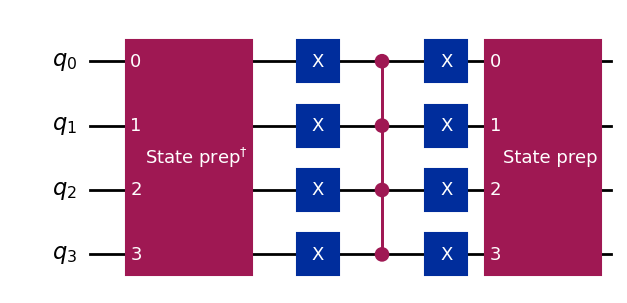

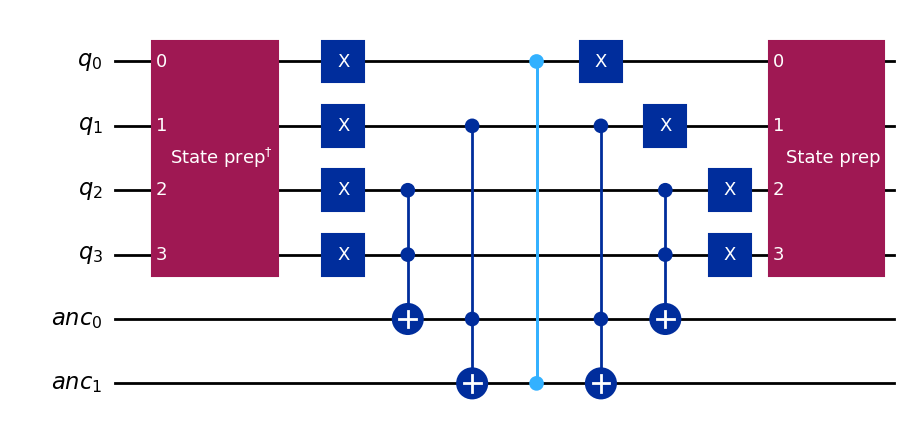

time: 940 ms (started: 2026-10-30 08:37:57 +00:00)


In [33]:
# ===== Diffusion circuit with the multi-controlled Z (no ancillas) - figure for the paper (2x2 grid, 4 qubits) =====
from qiskit.circuit import Gate
from qiskit.circuit.library import ZGate

n = 4
# Generic boxes for the state preparation A and its inverse A^dagger (drawing only)
state_prep_box = Gate("state_prep", n, [], label=r"State prep")
state_prep_dg_box = Gate("state_prep_dg", n, [], label=r"State prep$^{\dagger}$")

diffusion = QuantumCircuit(n)
diffusion.append(state_prep_dg_box, range(n))
diffusion.x(range(n))
diffusion.append(ZGate().control(n - 1), range(n))
diffusion.x(range(n))
diffusion.append(state_prep_box, range(n))

fig = diffusion.draw("mpl")
fig.savefig("diffusion_mcz_2x2.pdf", bbox_inches="tight")
fig.savefig("diffusion_mcz_2x2.png", dpi=300, bbox_inches="tight")
display(fig)

# ===== Previous diffusion with cnz (Toffoli chain on 2 ancillas) - same 2x2 grid, for comparison =====
q = QuantumRegister(n, 'q')
anc = QuantumRegister(n - 2, 'anc')
diffusion_cnz = QuantumCircuit(q, anc)
diffusion_cnz.append(state_prep_dg_box, q)
diffusion_cnz.x(q)
cnz(diffusion_cnz, n - 1, q[::-1], anc)
diffusion_cnz.x(q)
diffusion_cnz.append(state_prep_box, q)

fig_cnz = diffusion_cnz.draw("mpl")
fig_cnz.savefig("diffusion_cnz_2x2.pdf", bbox_inches="tight")
fig_cnz.savefig("diffusion_cnz_2x2.png", dpi=300, bbox_inches="tight")
display(fig_cnz)

4 qubits: C^3Z == H . C^3X . H  -> True
9 qubits: C^8Z == H . C^8X . H  -> True
Exact distance (TVD) vs 'ancilla (cnz, 7 anc)': 1.80e-15
Exact distance (TVD) vs 'mcz (no anc, 15 qubits)': 1.77e-15


version,"ancilla (cnz, 7 anc)","mcz (no anc, 15 qubits)","mcx (H + C^8X + H, 15 qubits)"
qubits_declared,17.00,15.00,15.00
gates_total,17533.00,17356.00,17356.00
cx (2-qubit),4275.00,4186.00,4186.00
depth,16625.00,16586.00,16589.00
p_valid_dungeon,1.00,1.00,1.00
valid_outcomes_measured,188.00,188.00,188.00
invalid_outcomes_measured,0.00,0.00,0.00
t_run_s (median),2.44,0.85,0.81


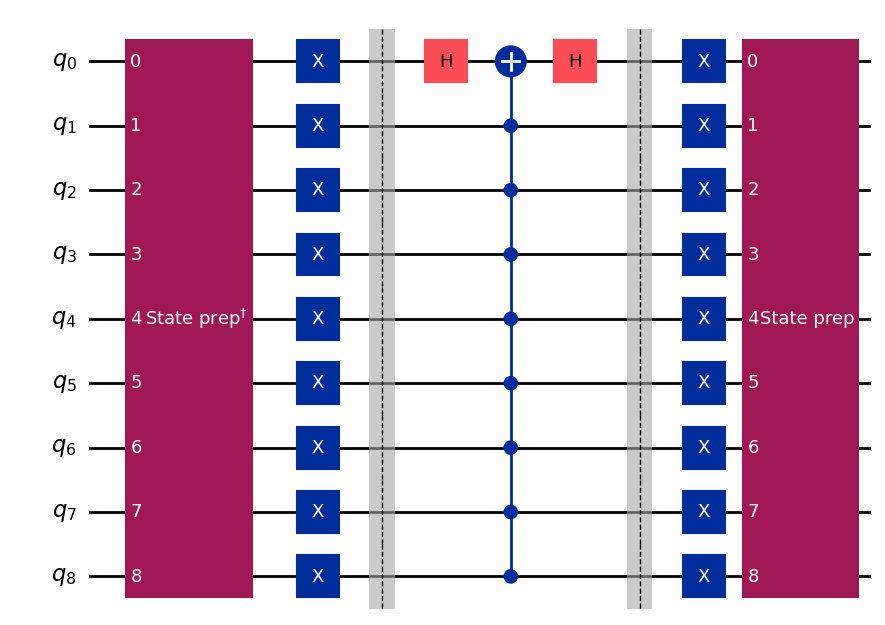

time: 13.7 s (started: 2026-10-30 08:56:08 +00:00)


In [37]:
# ===== Check: C^{n-1}Z == H(target) . C^{n-1}X . H(target)  (lecture form of the diffusion) =====
from qiskit.circuit.library import XGate, ZGate
from qiskit.quantum_info import Operator

def mcz_as_mcx(n):
    """Multi-controlled Z written as H + C^{n-1}NOT + H on the target qubit q0 (controls q1..q_{n-1})."""
    qc = QuantumCircuit(n)
    qc.h(0)
    qc.append(XGate().control(n - 1), list(range(1, n)) + [0])
    qc.h(0)
    return qc

for n_q in [4, 9]:
    ref = QuantumCircuit(n_q)
    ref.append(ZGate().control(n_q - 1), range(n_q))
    print(f"{n_q} qubits: C^{n_q-1}Z == H . C^{n_q-1}X . H  ->", Operator(ref).equiv(Operator(mcz_as_mcx(n_q))))

# Full recycling circuit (3 iterations) with the lecture form of the diffusion, compared with the other two
results = [r for r in results if not r["version"].startswith("mcx")]   # avoid duplicates if the cell is re-run
results.append(analyse_recycling("mcx (H + C^8X + H, 15 qubits)", ITERATIONS, "mcx"))
ref_anc, ref_mcz, r_mcx = results[0], results[1], results[-1]
print(f"Exact distance (TVD) vs '{ref_anc['version']}': {0.5 * np.abs(ref_anc['_probs'] - r_mcx['_probs']).sum():.2e}")
print(f"Exact distance (TVD) vs '{ref_mcz['version']}': {0.5 * np.abs(ref_mcz['_probs'] - r_mcx['_probs']).sum():.2e}")
cols = ["version", "qubits_declared", "gates_total", "cx (2-qubit)", "depth", "p_valid_dungeon",
        "valid_outcomes_measured", "invalid_outcomes_measured", "t_run_s (median)"]
df_mcx = pd.DataFrame([{k: r[k] for k in cols} for r in (ref_anc, ref_mcz, r_mcx)])
display(df_mcx.set_index("version").T)
df_mcx.to_csv("recycling_diffusion_mcx_check.csv", index=False)

# Figure (default Qiskit style, 3x3 grid = 9 qubits): State prep^dagger, X, H(q0), C^8X (target q0), H(q0), X, State prep
n9 = 9
state_prep_box9 = Gate("state_prep", n9, [], label=r"State prep")
state_prep_dg_box9 = Gate("state_prep_dg", n9, [], label=r"State prep$^{\dagger}$")
diffusion_mcx = QuantumCircuit(n9)
diffusion_mcx.append(state_prep_dg_box9, range(n9))
diffusion_mcx.x(range(n9))
diffusion_mcx.barrier()
diffusion_mcx.h(0)
diffusion_mcx.append(XGate().control(n9 - 1), list(range(1, n9)) + [0])
diffusion_mcx.h(0)
diffusion_mcx.barrier()
diffusion_mcx.x(range(n9))
diffusion_mcx.append(state_prep_box9, range(n9))
fig_mcx = diffusion_mcx.draw("mpl")
fig_mcx.savefig("diffusion_mcx_3x3.pdf", bbox_inches="tight")
fig_mcx.savefig("diffusion_mcx_3x3.png", dpi=300, bbox_inches="tight")
display(fig_mcx)

Oracle check on all 512 grid states (phase -1 iff >= 2 rooms, ancillas restored): True


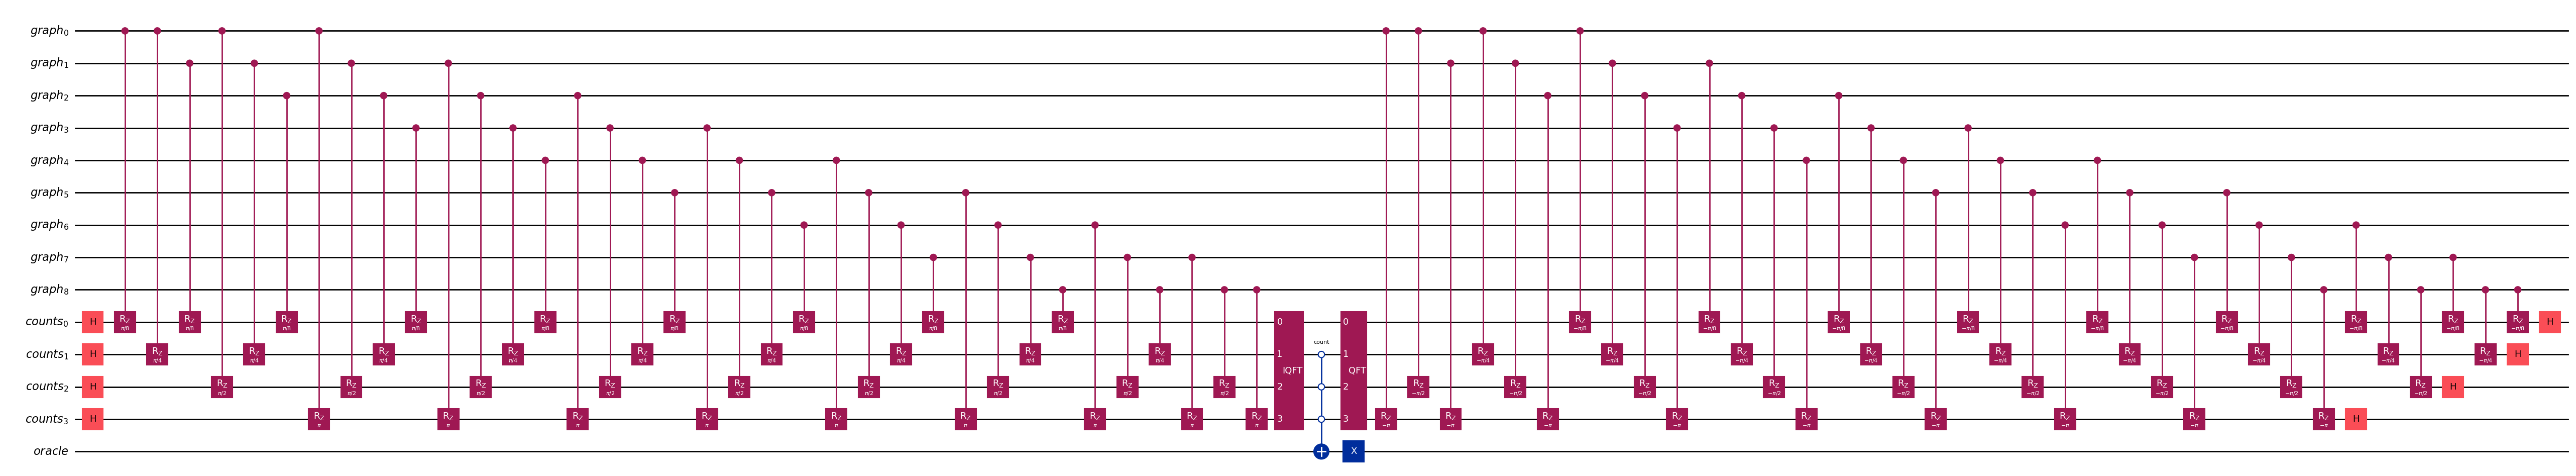

time: 26.5 s (started: 2026-10-30 09:06:41 +00:00)


In [38]:
# ===== Oracle for the 3x3 grid with the constraint "at least two rooms" - figure for the paper =====
from qiskit.circuit.library import QFT, MCXGate
from qiskit.quantum_info import Statevector

n_graph = 9
n_count = 4          # 4 count qubits: values 0..15, enough to count up to 9 rooms without wrap-around
g_reg = QuantumRegister(n_graph, 'graph')
c_reg = QuantumRegister(n_count, 'counts')
o_reg = QuantumRegister(1, 'oracle')
oracle_3x3 = QuantumCircuit(g_reg, c_reg, o_reg)

# Room count (QFT-based adder): each room adds 1 to the counter in the Fourier basis
oracle_3x3.h(c_reg)
for qubit in g_reg:
    for k in range(n_count):
        oracle_3x3.crz(np.pi * 2**k / 2**(n_count - 1), qubit, c_reg[k])   # pi/8, pi/4, pi/2, pi
qft_o = QFT(n_count, do_swaps=True, inverse=True)
oracle_3x3.append(qft_o.to_instruction(), c_reg)

# "At least two rooms" <=> count >= 2 <=> NOT(counts_1 = counts_2 = counts_3 = 0)
# -> flip the oracle when the three most significant count qubits are all 0, then flip it back with X
mcx_o = MCXGate(n_count - 1, "count", "0" * (n_count - 1))
oracle_3x3.append(mcx_o, list(c_reg[1:]) + [o_reg[0]])
oracle_3x3.x(o_reg)

# Uncompute the counter
oracle_3x3.append(qft_o.inverse().to_instruction(), c_reg)
for qubit in g_reg:
    for k in reversed(range(n_count)):
        oracle_3x3.crz(-np.pi * 2**k / 2**(n_count - 1), qubit, c_reg[k])
oracle_3x3.h(c_reg)

# Check: with the oracle qubit in |->, every grid configuration with >= 2 rooms gets phase -1,
# all the others +1, and the count qubits are back to |0>
ok = True
for x in range(2**n_graph):
    init = QuantumCircuit(g_reg, c_reg, o_reg)
    for i in range(n_graph):
        if (x >> i) & 1:
            init.x(g_reg[i])
    init.x(o_reg); init.h(o_reg)
    sv_in = Statevector(init)
    sv_out = sv_in.evolve(oracle_3x3)
    phase = np.vdot(sv_in.data, sv_out.data)
    expected = -1 if bin(x).count('1') >= 2 else 1
    ok &= np.isclose(phase, expected)
print("Oracle check on all 512 grid states (phase -1 iff >= 2 rooms, ancillas restored):", ok)

fig_oracle = oracle_3x3.draw("mpl", fold=-1)
fig_oracle.savefig("oracle_3x3_at_least_2.pdf", bbox_inches="tight")
fig_oracle.savefig("oracle_3x3_at_least_2.png", dpi=300, bbox_inches="tight")
display(fig_oracle)

In [39]:
ok# ===== Timing of the paper circuit: cells 0 and 1 occupied + exactly 4 rooms, MCZ diffusion (15 qubits) =====
from qiskit.circuit.library import ZGate

def build_paper_circuit(num_iterations):
    graph = QuantumRegister(9, 'graph')
    const_anc = QuantumRegister(2, 'c_anc')      # occupied-rooms ancilla + final count ancilla
    oracle = QuantumRegister(1, 'oracle')
    cnt = QuantumRegister(3, 'count')
    c = ClassicalRegister(9, 'c')
    qc = QuantumCircuit(graph, const_anc, oracle, cnt, c)
    qc.append(stat_prep, graph)
    qc.x(oracle)
    qc.h(oracle)
    qft = QFT(3, do_swaps=True, inverse=True)
    mcx = MCXGate(3, "count", "100")
    for _ in range(num_iterations):
        # Oracle: cells 0 and 1 occupied (qubits 7, 8 in Qiskit order) and exactly 4 rooms
        qc.ccx(graph[7], graph[8], const_anc[0])
        qc.h(cnt)
        for qubit in graph:
            qc.crz(np.pi/4, qubit, cnt[0])
            qc.crz(np.pi/2, qubit, cnt[1])
            qc.crz(np.pi, qubit, cnt[2])
        qc.append(qft.to_instruction(), cnt)
        qc.append(mcx, qargs=[cnt[0], cnt[1], cnt[2], const_anc[1]])
        qc.ccx(const_anc[0], const_anc[1], oracle[0])
        qc.append(mcx, qargs=[cnt[0], cnt[1], cnt[2], const_anc[1]])
        qc.append(qft.inverse().to_instruction(), cnt)
        for qubit in graph:
            qc.crz(-np.pi, qubit, cnt[2])
            qc.crz(-np.pi/2, qubit, cnt[1])
            qc.crz(-np.pi/4, qubit, cnt[0])
        qc.h(cnt)
        qc.ccx(graph[7], graph[8], const_anc[0])
        # Diffusion: State prep^dagger, X, MCZ (no ancillas), X, State prep
        qc.append(inv_stat_prep, range(9))
        qc.x(range(9))
        qc.append(ZGate().control(8), graph)
        qc.x(range(9))
        qc.append(stat_prep, range(9))
    qc.measure(graph, c)
    return qc

valid = global_state_vector == 1
target = np.array([bool(valid[i] and bin(i).count("1") == 4 and (i >> 7) & 1 and (i >> 8) & 1) for i in range(512)])
M, N = int(target.sum()), int(valid.sum())
theta = np.arcsin(np.sqrt(M / N))
print(f"Target dungeons M = {M} out of N = {N}; optimal iterations ~ pi/(4 theta) - 1/2 = {np.pi / (4 * theta) - 0.5:.2f}")

sim = Aer.get_backend('qasm_simulator')
rows = []
for k in [4, 5]:
    qc = build_paper_circuit(k)
    hw = transpile(qc, basis_gates=['rz', 'sx', 'x', 'cx'], optimization_level=1, seed_transpiler=42)
    ops = {o: v for o, v in hw.count_ops().items() if o not in ('measure', 'barrier')}
    p = graph_probs(qc)
    t0 = time.perf_counter(); tqc = transpile(qc, sim); t_tr = time.perf_counter() - t0
    wall, aer = [], []
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        res = sim.run(tqc, shots=9**4, seed_simulator=42).result()
        wall.append(time.perf_counter() - t0); aer.append(res.time_taken)
    cnts = res.get_counts()
    rows.append({"iterations": k, "qubits": qc.num_qubits, "gates_total": sum(ops.values()),
                 "cx (2-qubit)": ops.get('cx', 0), "depth": hw.depth(),
                 "p_success (exact)": round(float(p[target].sum()), 4),
                 "p_success (theory)": round(float(np.sin((2 * k + 1) * theta) ** 2), 4),
                 "p_success (9^4 shots)": round(sum(v for s, v in cnts.items() if target[int(s, 2)]) / 9**4, 4),
                 "t_transpile_s": round(t_tr, 2),
                 "t_run_s (median)": round(float(np.median(wall)), 2),
                 "t_run_s (all)": [round(w, 2) for w in wall]})
df_paper = pd.DataFrame(rows)
display(df_paper.set_index("iterations").T)
df_paper.to_csv("paper_circuit_mcz_timing.csv", index=False)
print("Device:", sim.options.device)

Target dungeons M = 7 out of N = 188; optimal iterations ~ pi/(4 theta) - 1/2 = 3.54


iterations,4,5
qubits,15,15
gates_total,22391,27426
cx (2-qubit),5414,6642
depth,21186,25930
p_success (exact),0.9691,0.7132
p_success (theory),0.9691,0.7132
p_success (9^4 shots),0.971,0.7148
t_transpile_s,2.8,3.38
t_run_s (median),1.07,1.25
t_run_s (all),"[1.08, 1.07, 1.03]","[1.32, 1.25, 1.25]"


Device: CPU
time: 30.9 s (started: 2026-10-30 09:25:47 +00:00)
